In [1]:
import pybamm
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from DFN import DFN

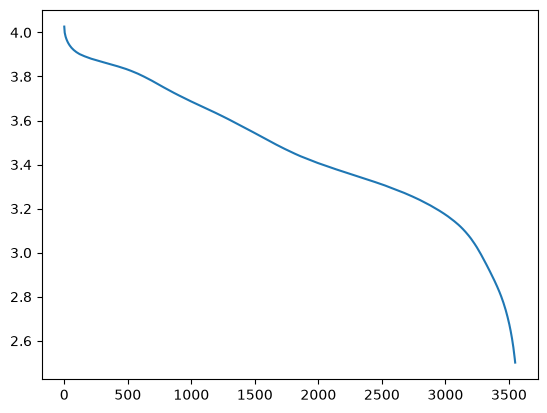

In [2]:
data_exp = pd.read_csv("LGM50_cell02.csv")
data1C = data_exp[data_exp["Step"] >= 17]
data1C = data1C[data1C["Step"] <= 18]
data1C["Test Time [s]"] = data1C["Test Time [s]"] - data1C["Test Time [s]"].iloc[0]
data1C = data1C[data1C["Test Time [s]"] <= 4000]

t_exp, v_exp = data1C["Test Time [s]"], data1C["Voltage [V]"]

filt = np.gradient(v_exp) < 0

t_exp, v_exp = t_exp[filt], v_exp[filt]

t_eval = np.linspace(0, t_exp.max(), 1001)

v_exp = np.interp(t_eval, t_exp, v_exp)

plt.plot(t_eval, v_exp)

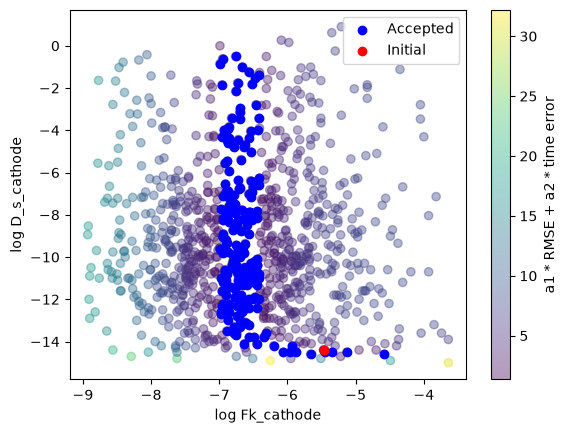

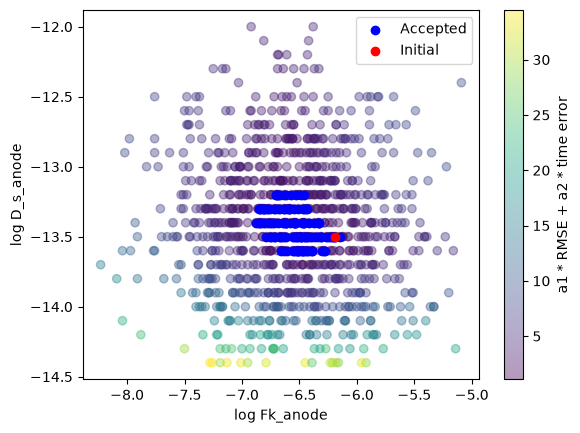

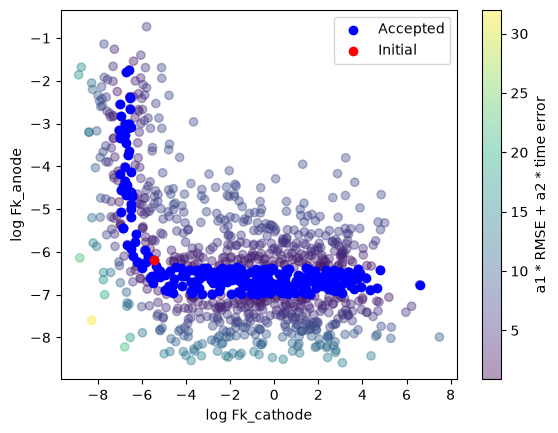

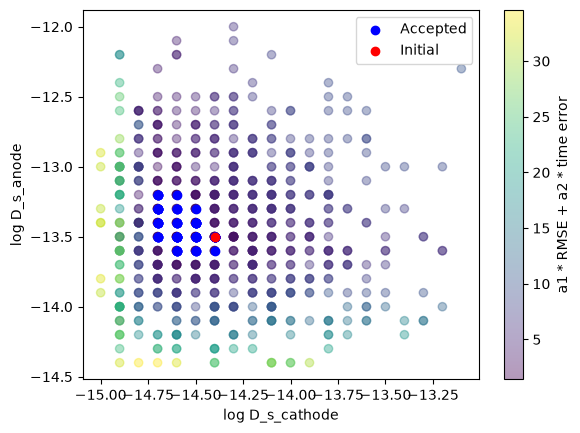

In [3]:
for name0, name1 in [
        ("Fk_cathode", "D_s_cathode"),
        ("Fk_anode", "D_s_anode"),
        ("Fk_cathode", "Fk_anode"),
        ("D_s_cathode", "D_s_anode")
    ]:
    data = np.loadtxt(f"data_metropolis/{name0}-{name1}.data")
    theta0 = data[:, 0]
    theta1 = data[:, 1]
    error = data[:, 2]
    accepted = data[:, 3]

    plt.figure()
    plt.colorbar(plt.scatter(theta0, theta1, c=error, alpha=0.4), label="a1 * RMSE + a2 * time error")

    plt.scatter(theta0[accepted.astype(bool)], theta1[accepted.astype(bool)], c='blue', label="Accepted")
    plt.scatter(theta0[0], theta1[0], c='red', label="Initial")
    plt.xlabel("log " + name0)
    plt.ylabel("log " + name1)
    plt.legend()